# 02 · Polynomial logistic regression: approximation is not the problem (Figure 2)

**Hypothesis H1.** The mock paper's polynomial models fail because of *sample complexity in the irrelevant
coordinates*, not because polynomials cannot represent the label function.

**Design.** One controlled change at a time, everything else identical to the mock paper (normalised
`PolynomialFeatures` kernel, logistic loss, $C=0.85$):
1. *Reproduction*: the mock model on all $n$ bits, degrees 1–10, on the mock paper's own split.
2. *Intervention 1*: the same model on the 10 coordinates selected from training/validation data only.
3. *Intervention 2*: additionally choose $C\in\{0.85,10,10^2,10^3,10^4\}$ on the validation set.
4. *Theory*: the infinite-data limit of degree-$d$ logistic regression, computed on the population.

Interventions 1–2 are repeated on the 5 stratified 60/20/20 splits (seeds 0–4); test sets are used only for
the final numbers.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

from krypto.data import load, split, mock_split, NS, SEEDS, TARGET
from krypto.polynomial import mock_kernel_accuracies, parity_features
from krypto.selection import greedy_forward_selection
from krypto.fourier import truth_table
from krypto.stats import mean_ci, save_json
from krypto.energy import track
from krypto.plotting import use_paper_style, save, FULL, COLORS, pct

print("plot backend:", use_paper_style())
DEGREES = list(range(1, 11))
C_GRID = [0.85, 10, 100, 1000, 10000]

plot backend: usetex


## 1. Reproduction of the mock paper's Figure 1 (all $n$ bits, mock split)
This is the mock paper's code, unchanged (`krypto/polynomial.py`).  It needs ~4 GB of memory for $n=40$.

In [2]:
mock = {}
for n in NS:
    X, y = load(f"kryptonite-{n}")
    X_tr, y_tr, _, _, X_te, y_te = mock_split(X, y)
    with track(f"02_mock_kernel_n{n}"):
        mock[n] = mock_kernel_accuracies(X_tr, y_tr, X_te, y_te, DEGREES)
save_json({str(n): v for n, v in mock.items()}, "poly_mock_reproduction.json")

n=20 degree=1 features=21 accuracy=0.503


n=20 degree=2 features=231 accuracy=0.553


n=20 degree=3 features=1,771 accuracy=0.556


n=20 degree=4 features=10,626 accuracy=0.573


n=20 degree=5 features=53,130 accuracy=0.570


n=20 degree=6 features=230,230 accuracy=0.580


... (23 outputs left out)

n=40 degree=8 features=377,348,994 accuracy=0.541


n=40 degree=9 features=2,054,455,634 accuracy=0.525


n=40 degree=10 features=10,272,278,170 accuracy=0.541


[track] 02_mock_kernel_n40: 492.4 s


## 2. The same model on the selected coordinates (5 splits)
On $k=10$ bits the normalised polynomial kernel has an explicit feature map with at most $2^{10}$ parity
features, so we fit it in the primal (identical solution to the dual; checked in `krypto/polynomial.py`).

In [3]:
sparse = {n: {"S": [], "fixed": {d: [] for d in DEGREES}, "tuned": {d: [] for d in DEGREES},
              "C": {d: [] for d in DEGREES}} for n in NS}
for n in NS:
    X, y = load(f"kryptonite-{n}")
    with track(f"02_sparse_poly_n{n}"):
        for seed in SEEDS:
            X_tr, y_tr, X_va, y_va, X_te, y_te = split(X, y, seed)
            S, _ = greedy_forward_selection(X_tr, y_tr, X_va, y_va)
            sparse[n]["S"].append(sorted(S))
            for d in DEGREES:
                F_tr, F_va, F_te = (parity_features(Z, S, d) for Z in (X_tr, X_va, X_te))
                fits = {C: LogisticRegression(C=C, fit_intercept=False, max_iter=5000, tol=1e-8).fit(F_tr, y_tr)
                        for C in C_GRID}
                best_C = max(C_GRID, key=lambda C: fits[C].score(F_va, y_va))
                sparse[n]["fixed"][d].append(fits[0.85].score(F_te, y_te))
                sparse[n]["tuned"][d].append(fits[best_C].score(F_te, y_te))
                sparse[n]["C"][d].append(best_C)
    print(f"n={n}: selected sets {sparse[n]['S']}")
    for d in DEGREES:
        m1, h1 = mean_ci(sparse[n]["fixed"][d]); m2, h2 = mean_ci(sparse[n]["tuned"][d])
        print(f"   d={d:2d}  all bits (mock split) {mock[n][d]:.3f} | selected, C=0.85 {m1:.3f}±{h1:.3f} | "
              f"selected, tuned C {m2:.3f}±{h2:.3f} (C chosen: {sparse[n]['C'][d]})")
save_json({str(n): {"S": v["S"], **{key: {str(d): v[key][d] for d in DEGREES} for key in ("fixed", "tuned", "C")}}
           for n, v in sparse.items()}, "poly_sparse.json")

[track] 02_sparse_poly_n20: 234.0 s
n=20: selected sets [[0, 1, 2, 4, 5, 7, 9, 10, 12, 15], [0, 1, 2, 4, 5, 7, 9, 10, 12, 15], [0, 1, 2, 4, 5, 7, 9, 10, 12, 15], [0, 1, 2, 4, 5, 7, 9, 10, 12, 15], [0, 1, 2, 4, 5, 7, 9, 10, 12, 15]]
   d= 1  all bits (mock split) 0.503 | selected, C=0.85 0.504±0.018 | selected, tuned C 0.504±0.018 (C chosen: [0.85, 0.85, 0.85, 0.85, 0.85])
   d= 2  all bits (mock split) 0.553 | selected, C=0.85 0.556±0.012 | selected, tuned C 0.556±0.012 (C chosen: [0.85, 0.85, 0.85, 0.85, 0.85])
   d= 3  all bits (mock split) 0.556 | selected, C=0.85 0.573±0.011 | selected, tuned C 0.573±0.010 (C chosen: [100, 0.85, 100, 10, 0.85])
   d= 4  all bits (mock split) 0.573 | selected, C=0.85 0.655±0.010 | selected, tuned C 0.678±0.012 (C chosen: [10, 100, 100, 1000, 1000])
   d= 5  all bits (mock split) 0.570 | selected, C=0.85 0.690±0.004 | selected, tuned C 0.792±0.010 (C chosen: [10000, 10000, 10000, 1000, 10000])
   d= 6  all bits (mock split) 0.580 | selected, C=0.85 0

[track] 02_sparse_poly_n30: 431.0 s
n=30: selected sets [[2, 5, 10, 11, 14, 17, 19, 20, 26, 28], [2, 5, 10, 11, 14, 17, 19, 20, 26, 28], [2, 5, 10, 11, 14, 17, 19, 20, 26, 28], [2, 5, 10, 11, 14, 17, 19, 20, 26, 28], [2, 5, 10, 11, 14, 17, 19, 20, 26, 28]]
   d= 1  all bits (mock split) 0.505 | selected, C=0.85 0.510±0.020 | selected, tuned C 0.510±0.020 (C chosen: [0.85, 0.85, 0.85, 0.85, 0.85])
   d= 2  all bits (mock split) 0.546 | selected, C=0.85 0.559±0.004 | selected, tuned C 0.559±0.004 (C chosen: [0.85, 0.85, 0.85, 0.85, 0.85])
   d= 3  all bits (mock split) 0.539 | selected, C=0.85 0.579±0.017 | selected, tuned C 0.581±0.017 (C chosen: [100, 0.85, 10, 10, 10])
   d= 4  all bits (mock split) 0.552 | selected, C=0.85 0.661±0.012 | selected, tuned C 0.671±0.008 (C chosen: [10, 100, 10, 100, 100])
   d= 5  all bits (mock split) 0.542 | selected, C=0.85 0.711±0.008 | selected, tuned C 0.788±0.010 (C chosen: [1000, 1000, 1000, 1000, 10000])
   d= 6  all bits (mock split) 0.553 | se

[track] 02_sparse_poly_n40: 1040.9 s
n=40: selected sets [[6, 7, 12, 15, 21, 24, 25, 30, 36, 39], [6, 7, 12, 15, 21, 24, 25, 30, 36, 39], [6, 7, 12, 15, 21, 24, 25, 30, 36, 39], [6, 7, 12, 15, 21, 24, 25, 30, 36, 39], [6, 7, 12, 15, 21, 24, 25, 30, 36, 39]]
   d= 1  all bits (mock split) 0.505 | selected, C=0.85 0.506±0.011 | selected, tuned C 0.506±0.011 (C chosen: [0.85, 0.85, 0.85, 0.85, 0.85])
   d= 2  all bits (mock split) 0.532 | selected, C=0.85 0.563±0.009 | selected, tuned C 0.563±0.009 (C chosen: [0.85, 0.85, 0.85, 0.85, 0.85])
   d= 3  all bits (mock split) 0.526 | selected, C=0.85 0.581±0.013 | selected, tuned C 0.582±0.013 (C chosen: [10, 0.85, 10, 10, 10])
   d= 4  all bits (mock split) 0.540 | selected, C=0.85 0.659±0.008 | selected, tuned C 0.664±0.010 (C chosen: [1000, 10, 100, 100, 1000])
   d= 5  all bits (mock split) 0.528 | selected, C=0.85 0.740±0.010 | selected, tuned C 0.784±0.005 (C chosen: [100, 10, 1000, 1000, 10000])
   d= 6  all bits (mock split) 0.541 | se

## 3. Infinite-data limit of degree-$d$ logistic regression
With unlimited data, (unregularised) logistic regression converges to the minimiser of the *population*
logistic loss over degree-$d$ polynomials.  Irrelevant bits are independent of the label, so they get zero
weight, and the population is the uniform distribution over the $2^{10}$ patterns of the relevant bits with
labels flipped at rate $\eta$.  We fit it exactly by weighting every pattern by $1-\eta$ (clean label) and
$\eta$ (flipped label).  For $d=2$ the minimiser is $c\,b_ib_j$ on the parity pair alone (all other degree-$\le 2$
coefficients of $f$ vanish), giving accuracy $\tfrac12(1+\tfrac{9}{64})(1-2\eta)+\eta$.

In [4]:
n_ref = max(NS)                       # the function is the same for every n (notebook 01); use the largest set
X, y = load(f"kryptonite-{n_ref}")
X_tr, y_tr, X_va, y_va, _, _ = split(X, y, 0)
S = sparse[n_ref]["S"][0]
tt = truth_table(np.r_[X_tr, X_va], np.r_[y_tr, y_va], S)          # majority label per pattern (+-1)
eta = float(np.mean((2 * np.r_[y_tr, y_va] - 1) != tt[(np.r_[X_tr, X_va][:, S] < 0).astype(int) @ (1 << np.arange(10))]))
patterns = np.where((np.arange(1024)[:, None] >> np.arange(10)) & 1, -1.0, 1.0)
X_pop = np.r_[patterns, patterns]                                      # bit patterns, used as inputs
y_pop = np.r_[(tt > 0).astype(int), (tt < 0).astype(int)]              # clean label, flipped label
w_pop = np.r_[np.full(1024, 1 - eta), np.full(1024, eta)]
limit = {}
for d in DEGREES:
    F = parity_features(X_pop, range(10), d)
    lr = LogisticRegression(C=1e6, fit_intercept=False, max_iter=20000, tol=1e-10).fit(F, y_pop, sample_weight=w_pop)
    clean = float(((lr.decision_function(F[:1024]) > 0) == (tt > 0)).mean())
    limit[d] = clean * (1 - 2 * eta) + eta
    print(f"d={d:2d}: population accuracy {limit[d]:.4f}  (noise-free agreement {clean:.4f})")
print(f"estimated label-noise rate eta = {eta:.4f}; closed form for d=2: {0.5 * (1 + 9 / 64) * (1 - 2 * eta) + eta:.4f}")
save_json({"eta": eta, "limit": {str(d): v for d, v in limit.items()}}, "poly_limit.json")

d= 1: population accuracy 0.5000  (noise-free agreement 0.5000)
d= 2: population accuracy 0.5648  (noise-free agreement 0.5703)
d= 3: population accuracy 0.5684  (noise-free agreement 0.5742)
d= 4: population accuracy 0.6729  (noise-free agreement 0.6875)


d= 5: population accuracy 0.7989  (noise-free agreement 0.8242)


d= 6: population accuracy 0.9501  (noise-free agreement 0.9883)


d= 7: population accuracy 0.9609  (noise-free agreement 1.0000)


d= 8: population accuracy 0.9609  (noise-free agreement 1.0000)


d= 9: population accuracy 0.9609  (noise-free agreement 1.0000)


d=10: population accuracy 0.9609  (noise-free agreement 1.0000)
estimated label-noise rate eta = 0.0391; closed form for d=2: 0.5648


## Figure 2

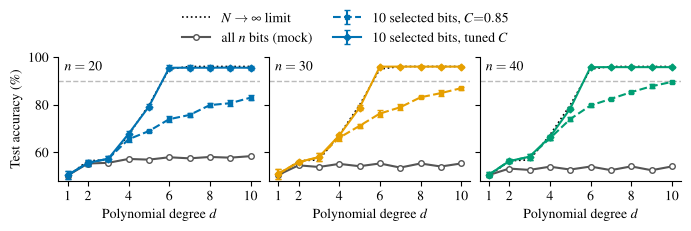

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(FULL, 2.2), sharey=True)
for ax, n in zip(axes, NS):
    ax.axhline(100 * TARGET, color="#bbbbbb", ls="--", lw=1)
    ax.plot(DEGREES, [100 * limit[d] for d in DEGREES], color="k", ls=":", lw=1.2, label=r"$N\to\infty$ limit")
    ax.plot(DEGREES, [100 * mock[n][d] for d in DEGREES], "o-", color=COLORS["gray"], mfc="white",
            label=r"all $n$ bits (mock)")
    for key, ls, mk, lab in (("fixed", "--", "s", r"10 selected bits, $C{=}0.85$"),
                             ("tuned", "-", "D", r"10 selected bits, tuned $C$")):
        stats = np.array([mean_ci(sparse[n][key][d]) for d in DEGREES]) * 100
        ax.errorbar(DEGREES, stats[:, 0], yerr=stats[:, 1], color=COLORS[n], ls=ls, marker=mk, ms=3.5,
                    capsize=2, label=lab)
    ax.set_xlabel("Polynomial degree $d$")
    ax.set_xticks([1, 2, 4, 6, 8, 10]); ax.set_ylim(48, 100)
    ax.text(0.03, 0.97, f"$n={n}$", transform=ax.transAxes, va="top")
axes[0].set_ylabel(pct("Test accuracy (%)"))
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=2, loc="outside upper center", handlelength=2.0, columnspacing=1.5)
save(fig, "fig2_polynomial")
plt.show()

**Reading Figure 2.** On all $n$ bits (grey) the mock paper's model stays near 55% at every degree, as the
mock paper reports.  Restricting the *same* model to the 10 selected coordinates lifts it to 82–92% at degree 10
even with the mock paper's strong regulariser, and to the Bayes level (~96%) once $C$ is chosen on validation
data, from degree 6 on — exactly the polynomial-threshold degree of $f$ (notebook 01).  The dotted line is the
infinite-data limit: polynomial logistic regression of degree $\ge 6$ *can* reach 96%; the mock paper's
models failed for lack of data relative to the $\binom{n+d}{d}$-dimensional feature space, not for lack of
expressive power.